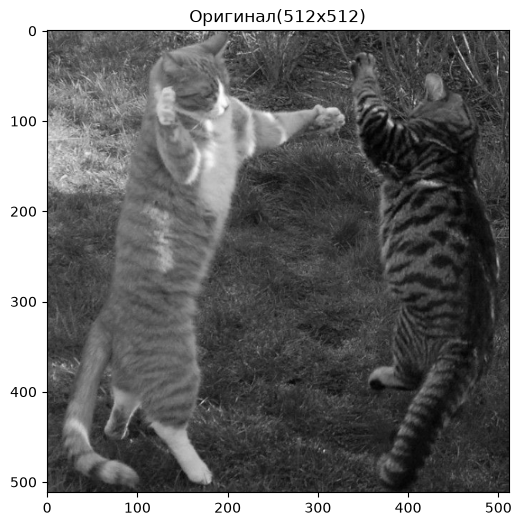

In [17]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy

img = cv2.imread('img_6_lab.jpg', cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img, (512, 512))
img_float = np.float32(img)

plt.figure(figsize=(6, 6))
plt.imshow(img_float, cmap='gray')
plt.title('Оригинал(512x512)')
plt.show()

In [11]:
# ф-ция 1-го шага преобразования Хаара
def haar_step(image):
    A = image[0::2, 0::2]
    B = image[0::2, 1::2]
    C = image[1::2, 0::2]
    D = image[1::2, 1::2]

    LL = (A + B + C + D) / 4.0
    HL = (A - B + C - D) / 4.0
    LH = (A + B - C - D) / 4.0
    HH = (A - B - C + D) / 4.0

    top = np.hstack((LL, HL))
    bottom = np.hstack((LH, HH))
    return np.vstack((top, bottom))

# ф-ция для вывода
def prepare_vis(haar_img, level):
    vis = np.abs(haar_img).copy()
    scale = 2 ** level
    ll_h, ll_w = 512 // scale, 512 // scale
    
    # маска:0 в левом верхнем углу(LL), 1 везде остальное
    mask = np.ones_like(vis)
    mask[0:ll_h, 0:ll_w] = 0
    
    # усиление деталей x5
    vis = vis + (vis * mask * 4.0)
    
    return np.clip(vis, 0, 255).astype(np.uint8)

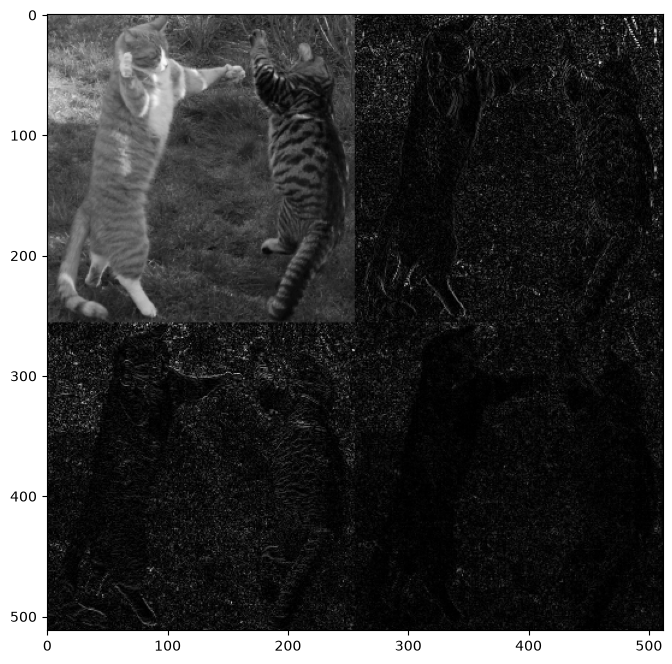

In [16]:
# преобразование ко всей картинке
step1 = haar_step(img_float)

plt.figure(figsize=(8, 8))
plt.imshow(prepare_vis(step1, level=1), cmap='gray')

Text(0.5, 1.0, 'Вторая ступень')

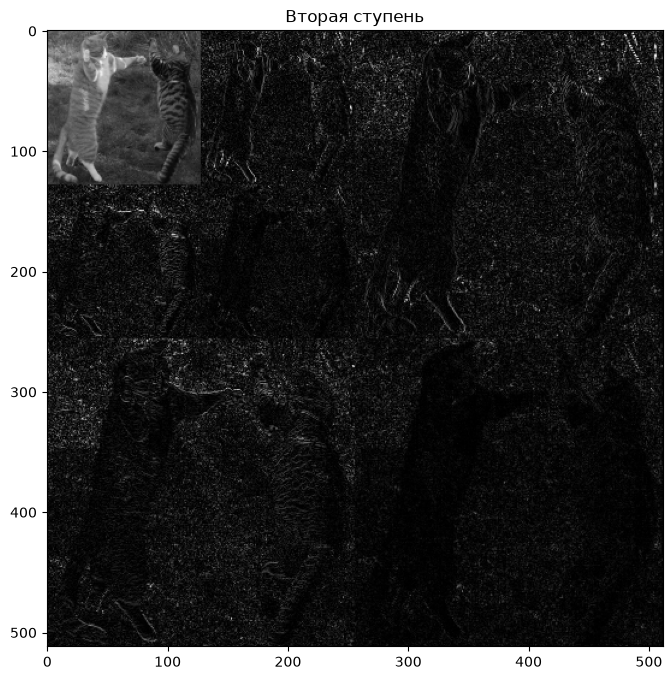

In [15]:
# копирование и применение функции только к левому верхнему углу
step2 = step1.copy()
half = 512 // 2
step2[:half, :half] = haar_step(step2[:half, :half])

plt.figure(figsize=(8, 8))
plt.imshow(prepare_vis(step2, level=2), cmap='gray')
plt.title('Вторая ступень')

Text(0.5, 1.0, 'Третья ступень')

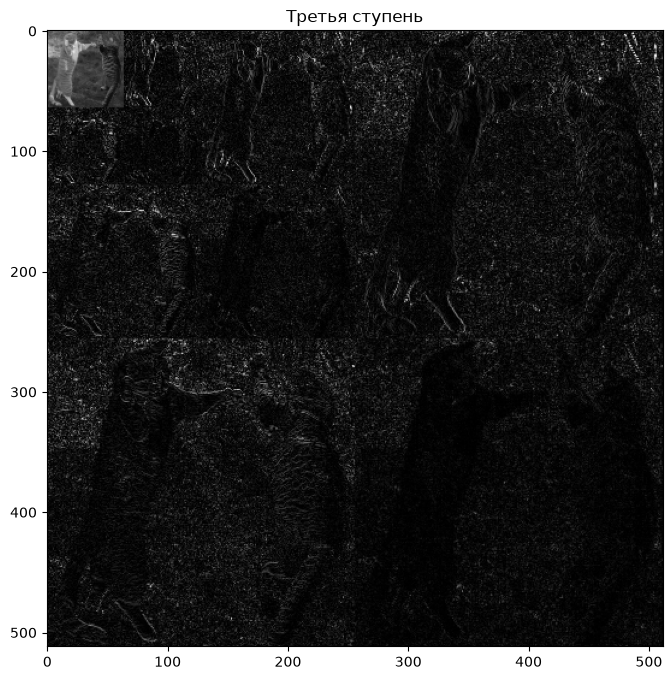

In [14]:
# копирование и применение функции к углу 128x128
step3 = step2.copy()
quarter = half // 2
step3[:quarter, :quarter] = haar_step(step3[:quarter, :quarter])

plt.figure(figsize=(8, 8))
plt.imshow(prepare_vis(step3, level=3), cmap='gray')
plt.title('Третья ступень')